# Notebook 5 — XGBoost Customer Churn Prediction
**IT3091 Machine Learning | Group 2026-DS-37 | Member 3**

**Primary goal:** Predict the probability of customer churn. **Secondary goal:** Support later high-risk customer profiling by explaining the chosen model.

This notebook uses the *same stratified 80/20 split* generated by Notebook 2 (`random_state=42`). All model selection and threshold exploration use the **training set only**. The 1,409-row held-out test set remains untouched until the group selects the final algorithm. This notebook includes a baseline, weighted/unweighted tuning, nested validation, threshold analysis, feature importance, saved files, and decision log.

**Run instructions:** Place this notebook under `notebooks/`, run `02_preprocessing.ipynb` beforehand, then select **Restart & Run All**. Nested validation runs many fits and may take several minutes. Do not treat provisional threshold comparisons as independent test estimates.

## 1. Imports and shared training-data validation

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss)

DATA_DIR = Path('../data/processed')
REPORT_DIR = Path('../reports')
MODEL_DIR = Path('../models')
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(DATA_DIR / 'X_train_raw.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv').squeeze('columns').astype(int)
assert X_train.shape == (5634, 19), f'Unexpected features: {X_train.shape}'
assert y_train.shape == (5634,), f'Unexpected labels: {y_train.shape}'
assert y_train.value_counts().to_dict() == {0: 4139, 1: 1495}
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
print('XGBoost:', xgb.__version__, '| scikit-learn:', sklearn.__version__)
print('Training features:', X_train.shape, 'Labels:', y_train.shape)
print('Class counts:', y_train.value_counts().to_dict())
print('Test split remains unopened for model selection.')

XGBoost: 3.4.1 | scikit-learn: 1.6.1
Training features: (5634, 19) Labels: (5634,)
Class counts: {0: 4139, 1: 1495}
Test split remains unopened for model selection.


## 2. Preprocessing and baseline model

One-hot encoding and imputation are fitted **inside the pipeline** on each CV training fold. Tree-based XGBoost does not require StandardScaler. `scale_pos_weight=1` is the unweighted baseline.

In [2]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

xgb_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', xgb.XGBClassifier(
        objective='binary:logistic', eval_metric='logloss',
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        scale_pos_weight=1.0, random_state=42, n_jobs=1
    ))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy':'accuracy', 'precision':'precision', 'recall':'recall',
           'f1':'f1', 'roc_auc':'roc_auc', 'average_precision':'average_precision'}
print('Numeric:', numeric_cols)
print('Categorical count:', len(categorical_cols))
print('Pipeline:', xgb_pipeline.named_steps.keys())

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical count: 15
Pipeline: dict_keys(['preprocessing', 'model'])


## 3. Baseline five-fold cross-validation

In [3]:
baseline_cv = cross_validate(xgb_pipeline, X_train, y_train,
                             cv=cv, scoring=scoring, n_jobs=1)
baseline_table = pd.DataFrame([
    {'Metric': k, 'Mean': baseline_cv['test_'+k].mean(),
     'Std': baseline_cv['test_'+k].std()}
    for k in scoring
])
print(baseline_table.round(4).to_string(index=False))

           Metric   Mean    Std
         accuracy 0.8032 0.0129
        precision 0.6600 0.0327
           recall 0.5338 0.0323
               f1 0.5898 0.0289
          roc_auc 0.8468 0.0102
average_precision 0.6667 0.0209


## 4. Model tuning (training-only)

The original notebook searched 16 hyperparameter combinations. We retain the same search space and add two options for imbalance weighting: unweighted and a training-derived ratio. The ratio is computed from the *shared training split*, never the test split. Stratified fold class ratios are nearly identical, but the ideal fold-specific ratio would be calculated separately inside each fitted estimator.

**Important:** `GridSearchCV.best_score_` is a *selection score*, not an unbiased final score.

In [4]:
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())
param_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [3, 4],
    'model__learning_rate': [0.03, 0.05],
    'model__min_child_weight': [1, 5],
    'model__subsample': [0.8],
    'model__colsample_bytree': [0.8],
    'model__scale_pos_weight': [1.0, class_ratio]
}
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(
    clone(xgb_pipeline), param_grid=param_grid,
    scoring='f1', cv=inner_cv, refit=True, n_jobs=1,
    return_train_score=False
)
search.fit(X_train, y_train)
print('Training class ratio:', round(class_ratio, 4))
print('Best training-search parameters:', search.best_params_)
print('Best mean inner CV F1 (optimistic selection score):', round(search.best_score_, 4))
tuning_table = (pd.DataFrame(search.cv_results_)
                .sort_values('rank_test_score')
                [['rank_test_score','mean_test_score','std_test_score','params']])
print(tuning_table.head(8).to_string(index=False))

Training class ratio: 2.7686
Best training-search parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__min_child_weight': 1, 'model__n_estimators': 200, 'model__scale_pos_weight': 2.768561872909699, 'model__subsample': 0.8}
Best mean inner CV F1 (optimistic selection score): 0.6391
 rank_test_score  mean_test_score  std_test_score                                                                                                                                                                                                                 params
               1         0.639086        0.013446 {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__min_child_weight': 1, 'model__n_estimators': 200, 'model__scale_pos_weight': 2.768561872909699, 'model__subsample': 0.8}
               2         0.638895        0.014217 {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 4

## 5. Nested five-fold validation for tuned XGBoost

For each outer fold, parameter tuning runs **only on the outer training portion**. Predictions for the outer validation portion come from a model that did not tune or train on those observations. This gives a more defensible estimate of the *tuning procedure* at a fixed threshold of 0.50.

This stage can take time: 5 outer folds × 3 inner folds × 32 parameter choices (plus refits). No test-set data is used.

In [5]:
nested_search = GridSearchCV(
    clone(xgb_pipeline), param_grid=param_grid, scoring='f1',
    cv=inner_cv, n_jobs=1, refit=True
)
outer_scores = cross_validate(
    nested_search, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1
)
nested_summary = pd.DataFrame([
    {'Metric': k, 'Mean': outer_scores['test_'+k].mean(),
     'Std': outer_scores['test_'+k].std()}
    for k in scoring
])
print('=== NESTED 5-FOLD SCORES AT THRESHOLD 0.50 ===')
print(nested_summary.round(4).to_string(index=False))

=== NESTED 5-FOLD SCORES AT THRESHOLD 0.50 ===
           Metric   Mean    Std
         accuracy 0.7536 0.0122
        precision 0.5236 0.0154
           recall 0.7960 0.0257
               f1 0.6316 0.0180
          roc_auc 0.8482 0.0104
average_precision 0.6691 0.0207


## 6. Threshold exploration using nested out-of-fold probabilities

Every outer-fold probability comes from a model whose tuning was confined to that fold's training partition. We **explore**, but do not conclusively validate, thresholds of 0.20–0.70. Picking the maximum F1 on this same table makes the chosen threshold's reported F1 somewhat optimistic. A final independent threshold assessment would require nested threshold selection or a dedicated validation set. Keep the 1,409-customer test set untouched.

In [6]:
oof_probabilities = cross_val_predict(
    nested_search, X_train, y_train, cv=cv,
    method='predict_proba', n_jobs=1
)[:, 1]
threshold_rows = []
for threshold in np.round(np.arange(0.20, 0.71, 0.05), 2):
    pred = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        'threshold': float(threshold),
        'accuracy': accuracy_score(y_train, pred),
        'precision': precision_score(y_train, pred, zero_division=0),
        'recall': recall_score(y_train, pred, zero_division=0),
        'f1': f1_score(y_train, pred, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)
provisional_row = threshold_df.loc[threshold_df['f1'].idxmax()]
provisional_threshold = float(provisional_row['threshold'])
print('=== EXPLORATORY THRESHOLD COMPARISON ===')
print(threshold_df.round(4).to_string(index=False))
print('\nProvisional highest-F1 threshold:', provisional_threshold)
print('Nested OOF ROC-AUC (threshold-free):', round(roc_auc_score(y_train, oof_probabilities), 4))
print('Nested OOF average precision:', round(average_precision_score(y_train, oof_probabilities), 4))
print('Nested OOF Brier score:', round(brier_score_loss(y_train, oof_probabilities), 4))
print('CAUTION: threshold-selected F1 is exploratory, not an independent estimate.')

=== EXPLORATORY THRESHOLD COMPARISON ===
 threshold  accuracy  precision  recall     f1
      0.20    0.6067     0.3981  0.9425 0.5598
      0.25    0.6415     0.4199  0.9211 0.5769
      0.30    0.6695     0.4401  0.9017 0.5915
      0.35    0.6961     0.4620  0.8823 0.6064
      0.40    0.7215     0.4860  0.8582 0.6206
      0.45    0.7405     0.5067  0.8321 0.6299
      0.50    0.7536     0.5235  0.7960 0.6316
      0.55    0.7703     0.5491  0.7512 0.6345
      0.60    0.7845     0.5789  0.6896 0.6294
      0.65    0.7994     0.6180  0.6395 0.6285
      0.70    0.8048     0.6495  0.5739 0.6094

Provisional highest-F1 threshold: 0.55
Nested OOF ROC-AUC (threshold-free): 0.8479
Nested OOF average precision: 0.6662
Nested OOF Brier score: 0.1593
CAUTION: threshold-selected F1 is exploratory, not an independent estimate.


## 7. Feature importance of the full-training selected pipeline

The search from Section 4 has refitted the selected configuration using all **training** observations. Its impurity/gain-based importance ranks *encoded features*. These values are not causal explanations, do not supply an effect direction, and may be distorted by redundant or correlated features. Use SHAP or permutation importance on the eventual winning model for the group's secondary profiling lens.

=== TOP 15 XGBOOST ENCODED FEATURES ===
                            Feature  Importance
       cat__Contract_Month-to-month      0.3701
             cat__OnlineSecurity_No      0.0789
   cat__InternetService_Fiber optic      0.0769
             cat__Contract_Two year      0.0526
           cat__InternetService_DSL      0.0414
                cat__TechSupport_No      0.0272
           cat__StreamingMovies_Yes      0.0272
             cat__Contract_One year      0.0225
cat__PaymentMethod_Electronic check      0.0205
            cat__InternetService_No      0.0191
                        num__tenure      0.0161
               cat__StreamingTV_Yes      0.0159
              cat__PhoneService_Yes      0.0147
          cat__PaperlessBilling_Yes      0.0120
             cat__MultipleLines_Yes      0.0114


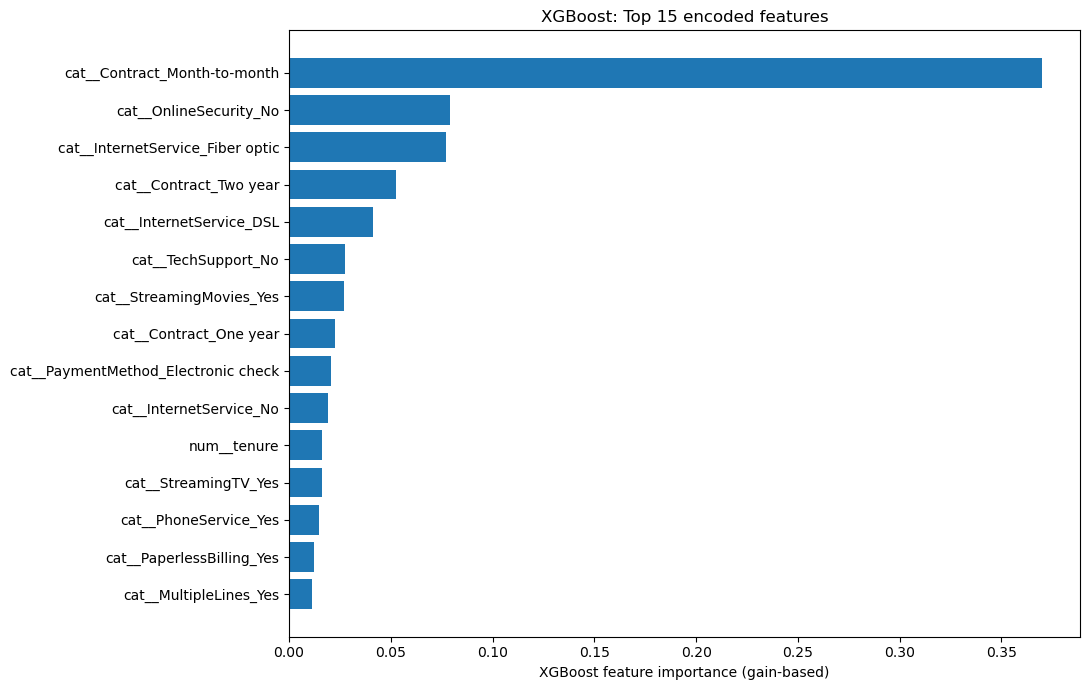

In [7]:
final_pipeline = search.best_estimator_
features = final_pipeline.named_steps['preprocessing'].get_feature_names_out()
importance_df = (pd.DataFrame({
    'Feature': features,
    'Importance': final_pipeline.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True))
print('=== TOP 15 XGBOOST ENCODED FEATURES ===')
print(importance_df.head(15).round(4).to_string(index=False))
plot_df = importance_df.head(15).iloc[::-1]
plt.figure(figsize=(11, 7))
plt.barh(plot_df['Feature'], plot_df['Importance'])
plt.xlabel('XGBoost feature importance (gain-based)')
plt.title('XGBoost: Top 15 encoded features')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'xgboost_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Compare evidence and save reproducible artifacts

Do **not** label the model as the overall winner yet. Member 3 must collect equivalent training-validation evidence from Logistic Regression, Random Forest, and Member 4's Decision Tree. The held-out test set is reserved for the *one selected final model*. Provisional threshold F1 values from other notebooks are not directly comparable to this notebook's nested tuning scores without a common evaluation protocol.

In [8]:
# Save the complete fitted training-only pipeline and associated evidence
joblib.dump(final_pipeline, MODEL_DIR / 'xgboost_pipeline.joblib')
threshold_df.to_csv(REPORT_DIR / 'xgboost_threshold_results.csv', index=False)
tuning_table.to_csv(REPORT_DIR / 'xgboost_tuning_results.csv', index=False)
nested_summary.to_csv(REPORT_DIR / 'xgboost_nested_cv_results.csv', index=False)
baseline_table.to_csv(REPORT_DIR / 'xgboost_baseline_cv_results.csv', index=False)
importance_df.to_csv(REPORT_DIR / 'xgboost_feature_importance.csv', index=False)

config = {
    'model': 'XGBoost', 'selected_parameters': search.best_params_,
    'provisional_threshold': provisional_threshold,
    'threshold_status': 'exploratory — selected using the same nested OOF predictions',
    'selection_metric': 'f1', 'test_set_used': False,
    'training_rows': int(len(X_train)), 'outer_folds': 5, 'inner_folds': 3
}
with open(MODEL_DIR / 'xgboost_config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2)
reloaded = joblib.load(MODEL_DIR / 'xgboost_pipeline.joblib')
assert np.allclose(reloaded.predict_proba(X_train.head(5)),
                   final_pipeline.predict_proba(X_train.head(5)))
print('Saved pipeline reload verified.')
print('Saved reports to:', REPORT_DIR.resolve())
print('Saved fitted model and provisional configuration to:', MODEL_DIR.resolve())

Saved pipeline reload verified.
Saved reports to: /Users/delshikankt/Desktop/Project_ML/telcom-churn/reports
Saved fitted model and provisional configuration to: /Users/delshikankt/Desktop/Project_ML/telcom-churn/models


## 9. Decision log and interpretation

| Decision | Reason | Evidence / limitation |
|---|---|---|
| Use shared raw train split | Fair comparisons and avoid leakage | 5,634 training customers; test set not loaded |
| Fit encoding within pipeline | Prevent learning categories from validation fold | OneHotEncoder fitted within each CV fold |
| Baseline XGBoost | Advanced boosted-tree alternative | Five-fold baseline metrics printed above |
| Tune depth, trees, rate and leaf constraints | Evaluate complexity choices | 16 base combinations × two weighting options |
| Consider positive-class weighting | Churn is minority class | Training class ratio only; near-constant stratified fold ratio |
| Nested CV | Avoid reusing tuning folds as independent evaluation | Five outer and three inner folds |
| Explore prediction thresholds | Retention may value recall differently from precision | Selected threshold is **provisional**, not unbiased |
| Use gain-based feature importance | Describe fitted model behavior | Not direction, causal explanation, or final SHAP analysis |
| Save results and fitted pipeline | Reproducibility and group handoff | Joblib model + CSVs + configuration |
